In [21]:
import os
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, recall_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import json
from sklearn.metrics import accuracy_score, precision_score, classification_report

In [22]:
print("Loading model and testing data...")
best_model = joblib.load('../artifacts/models/best_model.joblib')
X_test = pd.read_csv('../data/processed/X_test.csv')
y_test = pd.read_csv('../data/processed/y_test.csv').values.ravel()

# 2. Get prediction probabilities for Churn (positive class)
y_prob = best_model.predict_proba(X_test)[:, 1]
print(f"Data successfully loaded. Test matrix shape: {X_test.shape}")

Loading model and testing data...
Data successfully loaded. Test matrix shape: (1409, 29)


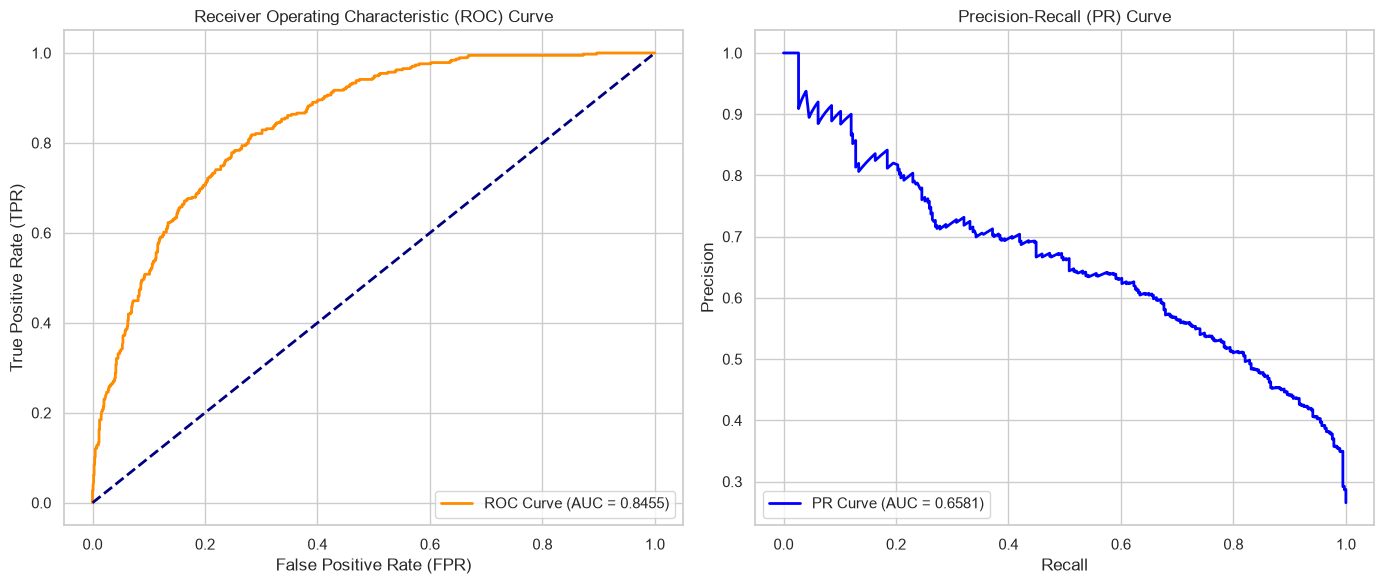

In [ ]:
# Set style configuration
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Plot ROC-AUC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[0].set_xlabel('False Positive Rate (FPR)')
axes[0].set_ylabel('True Positive Rate (TPR)')
axes[0].set_title('Receiver Operating Characteristic (ROC) Curve')
axes[0].legend(loc="lower right")

# 2. Plot Precision-Recall (PR) Curve
precision_vals, recall_vals, _ = precision_recall_curve(y_test, y_prob)
pr_auc = auc(recall_vals, precision_vals)
axes[1].plot(recall_vals, precision_vals, color='blue', lw=2, label=f'PR Curve (AUC = {pr_auc:.4f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall (PR) Curve')
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()


🎯 Optimal Threshold (Max F1-Score) Found: 0.60


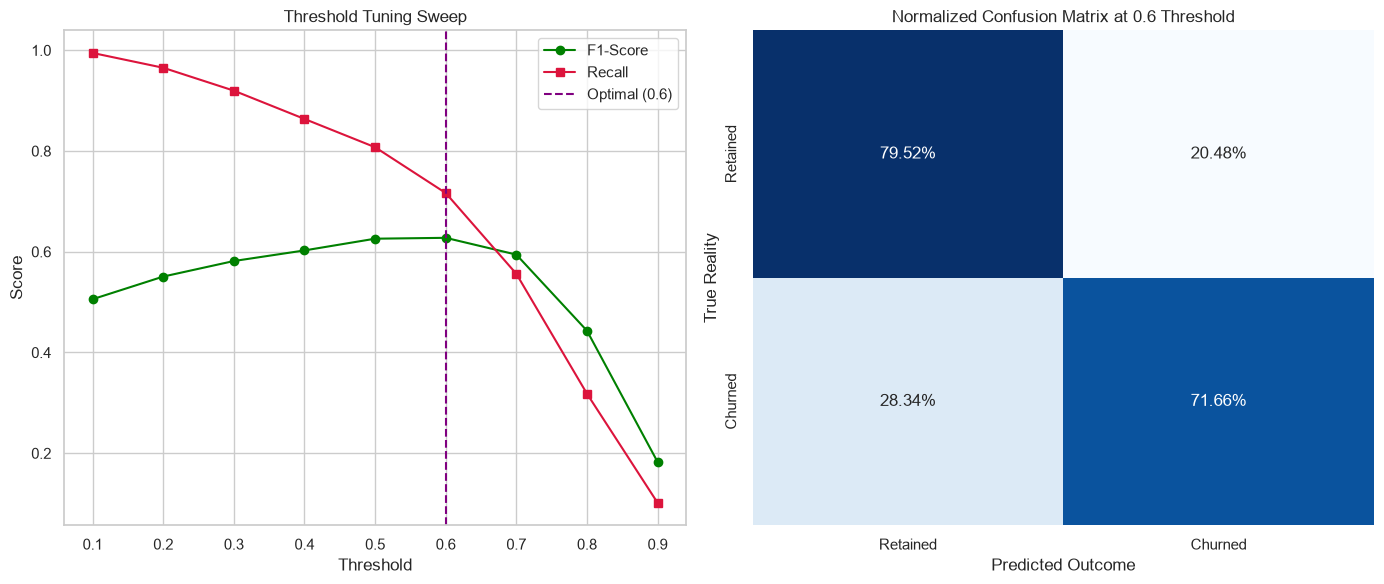

In [24]:


# 1. Sweep thresholds to balance F1-Score & Recall
threshold_sweep = np.arange(0.1, 1.0, 0.1)
f1_scores_list = []
recall_scores_list = []

best_f1 = 0
optimal_threshold = 0.5

for t in threshold_sweep:
    y_pred_t = (y_prob >= t).astype(int)
    f1_val = f1_score(y_test, y_pred_t, zero_division=0)
    rec_val = recall_score(y_test, y_pred_t, zero_division=0)
    
    f1_scores_list.append(f1_val)
    recall_scores_list.append(rec_val)
    
    if f1_val > best_f1:
        best_f1 = f1_val
        optimal_threshold = t

print(f"🎯 Optimal Threshold (Max F1-Score) Found: {optimal_threshold:.2f}")

# 2. Plot Matrix and Threshold Trade-off
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].plot(threshold_sweep, f1_scores_list, marker='o', label='F1-Score', color='green')
axes[0].plot(threshold_sweep, recall_scores_list, marker='s', label='Recall', color='crimson')
axes[0].axvline(optimal_threshold, color='purple', linestyle='--', label=f'Optimal ({optimal_threshold:.1f})')
axes[0].set_xlabel('Threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Threshold Tuning Sweep')
axes[0].legend()

# 3. Normalized Confusion Matrix at Optimal Threshold
y_pred_optimal = (y_prob >= optimal_threshold).astype(int)
cm_normalized = confusion_matrix(y_test, y_pred_optimal, normalize='true')

sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues", cbar=False,
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'], ax=axes[1])
axes[1].set_xlabel('Predicted Outcome')
axes[1].set_ylabel('True Reality')
axes[1].set_title(f'Normalized Confusion Matrix at {optimal_threshold} Threshold')

plt.tight_layout()
plt.show()


C:\Users\Administrator\AppData\Local\Temp\ipykernel_8888\2769256344.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')


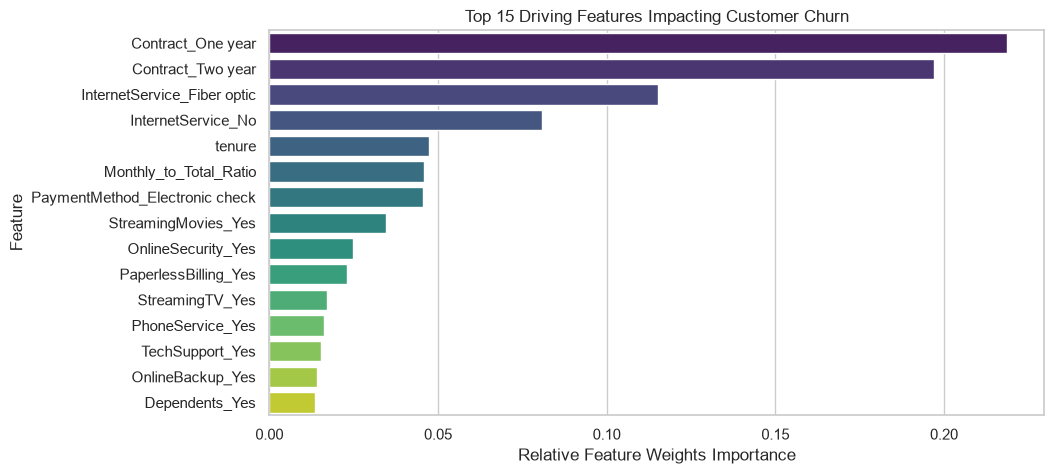


Classification Report metrics profile:
              precision    recall  f1-score   support

           0       0.89      0.80      0.84      1035
           1       0.56      0.72      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

🎉 Evaluation logging successfully stored at: ../artifacts/metrics/evaluation_metrics.json


In [25]:

# 1. Plot XGBoost Feature Importance
if hasattr(best_model, 'feature_importances_'):
    feat_imp_df = pd.DataFrame({'Feature': X_test.columns, 'Importance': best_model.feature_importances_})
    feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False).head(15)
    
    plt.figure(figsize=(10, 5))
    sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
    plt.title('Top 15 Driving Features Impacting Customer Churn')
    plt.xlabel('Relative Feature Weights Importance')
    plt.show()

# 2. Compile metrics into JSON configuration
metrics_summary_dict = {
    "Accuracy": float(accuracy_score(y_test, y_pred_optimal)),
    "ROC_AUC": float(roc_auc),
    "Precision": float(precision_score(y_test, y_pred_optimal, zero_division=0)),
    "Recall": float(recall_score(y_test, y_pred_optimal, zero_division=0)),
    "F1_Score": float(best_f1),
    "Optimal_Threshold": float(optimal_threshold)
}

# 3. Save JSON File with relative paths verification
metrics_dir = '../artifacts/metrics/'
os.makedirs(metrics_dir, exist_ok=True)
json_save_path = os.path.join(metrics_dir, 'evaluation_metrics.json')

with open(json_save_path, 'w') as json_file:
    json.dump(metrics_summary_dict, json_file, indent=4)

print("\n" + "="*50)
print("Classification Report metrics profile:")
print(classification_report(y_test, y_pred_optimal))
print(f"🎉 Evaluation logging successfully stored at: {json_save_path}")
print("="*50)
